# Домашнее задание
## Введение в статистику

**Школа аналитиков**

Тема: сравнение групп и статистическая проверка гипотез.



Стажёр Аналитик

Лашкин Даниил

## Задание 1. Одновыборочный Z-тест

Проверим гипотезу о том, что среднее время просмотра карточки вакансии составляет 120 секунд.

- **H₀:** μ = 120 — среднее время просмотра равно 120 секундам.
- **H₁:** μ ≠ 120 — среднее время просмотра отличается от 120 секунд.

Используем двустороннюю проверку гипотезы при уровне значимости α = 0.05.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

# Фиксируем генератор случайных чисел
rng = np.random.default_rng(7)

In [2]:
mu_0 = 120
sample_mean = 124
sigma = 25
n = 100
alpha = 0.05

# Стандартная ошибка среднего
se = sigma / np.sqrt(n)

# Z-статистика
z_stat = (sample_mean - mu_0) / se

# Двустороннее p-value
p_value = 2 * stats.norm.sf(abs(z_stat))

# Критическое значение
z_critical = stats.norm.ppf(1 - alpha / 2)

print("Стандартная ошибка:", round(se, 2))
print("Z-статистика:", round(z_stat, 2))
print("p-value:", round(p_value, 4))
print("Критические значения:", round(-z_critical, 2), "и", round(z_critical, 2))

Стандартная ошибка: 2.5
Z-статистика: 1.6
p-value: 0.1096
Критические значения: -1.96 и 1.96


### Вывод

Z-статистика равна 1.6. Это означает, что выборочное среднее время просмотра (124 секунды) находится на расстоянии 1.6 стандартной ошибки от предполагаемого значения 120 секунд.

Полученное p-value = 0.1096 больше уровня значимости α = 0.05.

Следовательно, оснований отвергать нулевую гипотезу H₀ нет. Статистически значимого отличия среднего времени просмотра от 120 секунд не обнаружено.

## Задание 2. Метод Уэлча

In [3]:
# Исходные данные
n1 = 40
mean1 = 50
s1 = 10

n2 = 40
mean2 = 55
s2 = 10

alpha = 0.05

# Разница средних: вторая группа минус первая
difference = mean2 - mean1

# Стандартная ошибка разницы
se = np.sqrt(s1**2 / n1 + s2**2 / n2)

# Степени свободы по формуле Уэлча
df = (s1**2 / n1 + s2**2 / n2)**2 / (
    (s1**2 / n1)**2 / (n1 - 1) +
    (s2**2 / n2)**2 / (n2 - 1)
)

# Критическое значение t
t_critical = stats.t.ppf(1 - alpha / 2, df)

# Границы 95% доверительного интервала
ci_low = difference - t_critical * se
ci_high = difference + t_critical * se

print("Разница средних:", round(difference, 4))
print("Стандартная ошибка:", round(se, 4))
print("Степени свободы:", round(df, 2))
print("Критическое значение t:", round(t_critical, 4))
print("95% доверительный интервал:",
      round(ci_low, 4), "-", round(ci_high, 4))

Разница средних: 5
Стандартная ошибка: 2.2361
Степени свободы: 78.0
Критическое значение t: 1.9908
95% доверительный интервал: 0.5483 - 9.4517


### Вывод

Разница средних между второй и первой группами составляет 5 единиц.

95% доверительный интервал по методу Уэлча: [0.55; 9.45].

Ноль не входит в доверительный интервал, следовательно, данные указывают на статистически значимое отличие средних двух групп.

Самый маленький положительный эффект, который ещё согласуется с данными, составляет примерно 0.55 единицы.

## Задание 3. Сравнение двух конверсий

Проверим, отличаются ли конверсии двух независимых групп.

- **H₀:** p₁ = p₂ — конверсии групп равны.
- **H₁:** p₁ ≠ p₂ — конверсии групп различаются.

Используем двусторонний Z-тест для двух независимых долей при уровне значимости α = 0.05.

In [4]:
# Исходные данные
successes = np.array([90, 120])
observations = np.array([1000, 1000])

alpha = 0.05

# Конверсии
p1 = successes[0] / observations[0]
p2 = successes[1] / observations[1]

# Разница конверсий
difference = p2 - p1

# Z-тест для двух независимых долей
z_stat, p_value = proportions_ztest(
    count=successes,
    nobs=observations,
    alternative="two-sided"
)

print("Конверсия первой группы:", round(p1 * 100, 2), "%")
print("Конверсия второй группы:", round(p2 * 100, 2), "%")
print("Разница конверсий:", round(difference * 100, 2), "п.п.")
print("Z-статистика:", round(z_stat, 4))
print("p-value:", round(p_value, 4))

if p_value < alpha:
    print("Отвергаем H0: конверсии статистически различаются.")
else:
    print("Нет оснований отвергать H0.")

Конверсия первой группы: 9.0 %
Конверсия второй группы: 12.0 %
Разница конверсий: 3.0 п.п.
Z-статистика: -2.1883
p-value: 0.0287
Отвергаем H0: конверсии статистически различаются.


### Вывод

Конверсия первой группы составила 9%, второй — 12%.

Разница между конверсиями составляет 3 процентных пункта в пользу второй группы.

Z-статистика равна 2.1883, p-value ≈ 0.0287.

Так как p-value меньше уровня значимости α = 0.05, отвергаем нулевую гипотезу H₀.

Следовательно, обнаружено статистически значимое различие между конверсиями двух групп. Конверсия второй группы выше.

## Задание 4. Симуляция при верной нулевой гипотезе

Проведём 2000 повторений эксперимента.

В каждом повторении создадим две независимые группы по 200 наблюдений из одного нормального распределения N(0, 1).

Для каждой пары групп выполним двусторонний t-тест Уэлча и сохраним полученное p-value.

Так как обе группы генерируются из одного распределения, нулевая гипотеза об отсутствии различий верна.

In [5]:
# Количество повторений эксперимента
n_simulations = 2000

# Размер каждой группы
n = 200

# Список для хранения p-value
p_values = []

# Повторяем эксперимент 2000 раз
for i in range(n_simulations):

    # Создаём две независимые группы из N(0, 1)
    group1 = rng.normal(loc=0, scale=1, size=n)
    group2 = rng.normal(loc=0, scale=1, size=n)

    # Выполняем t-тест Уэлча
    result = stats.ttest_ind(
        group1,
        group2,
        equal_var=False,
        alternative="two-sided"
    )

    # Сохраняем p-value
    p_values.append(result.pvalue)

# Преобразуем список в массив
p_values = np.array(p_values)

# Доля результатов, в которых p-value <= 0.05
significant_share = np.mean(p_values <= 0.05)

print("Количество симуляций:", n_simulations)
print("Среднее p-value:", round(np.mean(p_values), 4))
print("Доля p-value <= 0.05:", round(significant_share * 100, 2), "%")

Количество симуляций: 2000
Среднее p-value: 0.5119
Доля p-value <= 0.05: 5.7 %


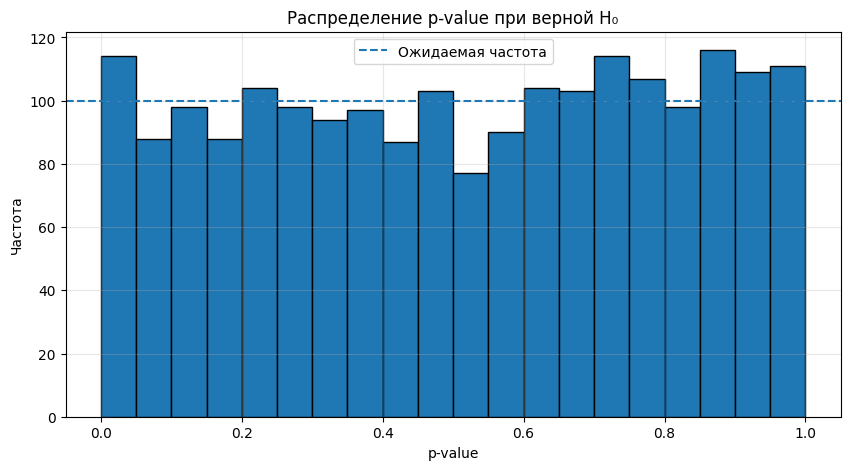

In [6]:
plt.figure(figsize=(10, 5))

plt.hist(
    p_values,
    bins=20,
    range=(0, 1),
    edgecolor="black"
)

plt.axhline(
    y=n_simulations / 20,
    linestyle="--",
    label="Ожидаемая частота"
)

plt.title("Распределение p-value при верной H₀")
plt.xlabel("p-value")
plt.ylabel("Частота")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Вывод

В ходе эксперимента было проведено 2000 симуляций. В каждой симуляции две независимые группы генерировались из одного нормального распределения N(0, 1).

Распределение p-value получилось приблизительно равномерным на отрезке от 0 до 1.

Так как нулевая гипотеза в данном эксперименте верна, примерно в 5% случаев p-value оказывается меньше или равно 0.05. Это связано с вероятностью ошибки первого рода при выбранном уровне значимости.

Таким образом, симуляция показывает, что при верной H₀ корректно работающий статистический тест может иногда ошибочно отвергать нулевую гипотезу.

## Задание 5. Влияние выбросов на статистические критерии

Проведём 1000 повторений эксперимента.

В каждом повторении:
- Создадим первую группу из 60 наблюдений N(0, 1).
- Создадим вторую группу из 60 наблюдений N(1, 1).
- Два случайных наблюдения второй группы заменим на -50.
- Рассчитаем разницу средних, t-статистику Уэлча и U-статистику Манна — Уитни.
- Сохраним p-value обоих критериев.

Для выбора двух наблюдений используем случайные индексы без повторений.

In [7]:
# Количество повторений
n_simulations = 1000

# Размер каждой группы
n = 60

# Списки для хранения результатов
mean_differences = []
t_statistics = []
u_statistics = []
welch_p_values = []
mannwhitney_p_values = []

for i in range(n_simulations):

    # Создаём две группы
    group1 = rng.normal(loc=0, scale=1, size=n)
    group2 = rng.normal(loc=1, scale=1, size=n)

    # Выбираем два разных случайных наблюдения
    # во второй группе и заменяем их на -50
    outlier_indices = rng.choice(n, size=2, replace=False)
    group2[outlier_indices] = -50

    # Разница средних: вторая группа минус первая
    mean_diff = group2.mean() - group1.mean()

    # Критерий Уэлча
    welch_result = stats.ttest_ind(
        group1,
        group2,
        equal_var=False,
        alternative="two-sided"
    )

    # Критерий Манна — Уитни
    # Первым аргументом передаём первую группу
    mw_result = stats.mannwhitneyu(
        group1,
        group2,
        alternative="two-sided"
    )

    # Сохраняем результаты
    mean_differences.append(mean_diff)
    t_statistics.append(welch_result.statistic)
    u_statistics.append(mw_result.statistic)
    welch_p_values.append(welch_result.pvalue)
    mannwhitney_p_values.append(mw_result.pvalue)


# Преобразуем списки в массивы
mean_differences = np.array(mean_differences)
t_statistics = np.array(t_statistics)
u_statistics = np.array(u_statistics)
welch_p_values = np.array(welch_p_values)
mannwhitney_p_values = np.array(mannwhitney_p_values)

print("Количество экспериментов:", n_simulations)
print("Средняя разница средних:", round(mean_differences.mean(), 4))
print("Средняя t-статистика:", round(t_statistics.mean(), 4))
print("Средняя U-статистика:", round(u_statistics.mean(), 2))

print("Доля значимых результатов Уэлча:",
      round(np.mean(welch_p_values <= 0.05) * 100, 2), "%")

print("Доля значимых результатов Манна — Уитни:",
      round(np.mean(mannwhitney_p_values <= 0.05) * 100, 2), "%")

Количество экспериментов: 1000
Средняя разница средних: -0.7
Средняя t-статистика: 0.5809
Средняя U-статистика: 957.03
Доля значимых результатов Уэлча: 0.0 %
Доля значимых результатов Манна — Уитни: 99.8 %


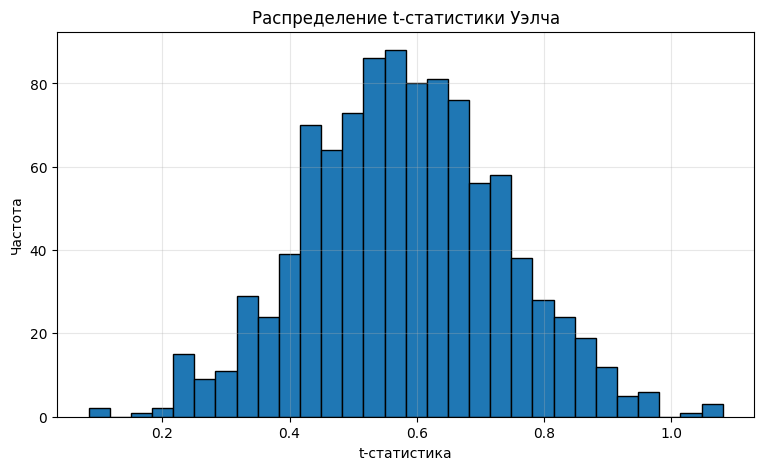

In [8]:
plt.figure(figsize=(9, 5))

plt.hist(t_statistics, bins=30, edgecolor="black")

plt.title("Распределение t-статистики Уэлча")
plt.xlabel("t-статистика")
plt.ylabel("Частота")
plt.grid(alpha=0.3)

plt.show()

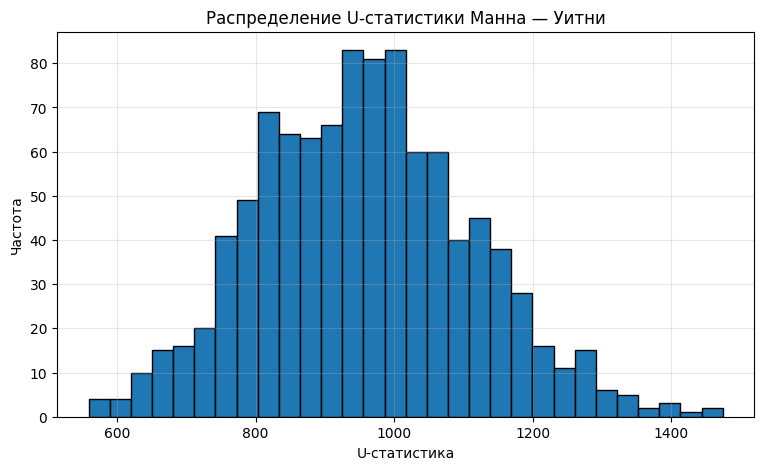

In [9]:
plt.figure(figsize=(9, 5))

plt.hist(u_statistics, bins=30, edgecolor="black")

plt.title("Распределение U-статистики Манна — Уитни")
plt.xlabel("U-статистика")
plt.ylabel("Частота")
plt.grid(alpha=0.3)

plt.show()

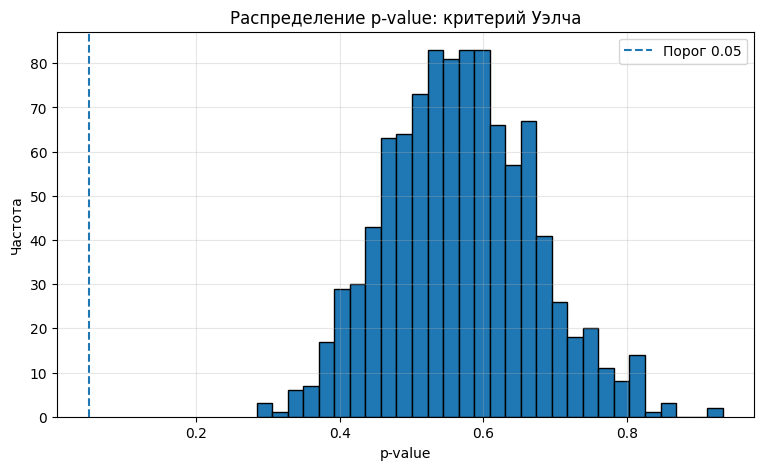

In [10]:
plt.figure(figsize=(9, 5))

plt.hist(welch_p_values, bins=30, edgecolor="black")
plt.axvline(0.05, linestyle="--", label="Порог 0.05")

plt.title("Распределение p-value: критерий Уэлча")
plt.xlabel("p-value")
plt.ylabel("Частота")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

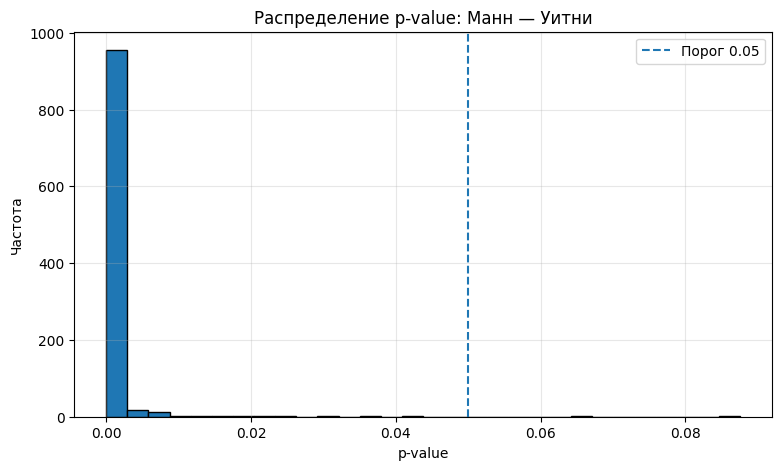

In [11]:
plt.figure(figsize=(9, 5))

plt.hist(mannwhitney_p_values, bins=30, edgecolor="black")
plt.axvline(0.05, linestyle="--", label="Порог 0.05")

plt.title("Распределение p-value: Манн — Уитни")
plt.xlabel("p-value")
plt.ylabel("Частота")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

### Вывод

В ходе 1000 экспериментов были сравнены критерий Уэлча и критерий Манна — Уитни при наличии двух экстремальных выбросов во второй группе

Критерий Уэлча чувствителен к выбросам, поскольку использует средние значения и стандартные отклонения. Экстремальные значения -50 существенно влияют на эти показатели

Критерий Манна — Уитни основан на рангах, поэтому он менее чувствителен к величине экстремальных выбросов

Результаты двух критериев могут различаться. При этом важно учитывать, что они проверяют разные гипотезы: Уэлч сравнивает средние, а Манн — Уитни сравнивает распределения

Таким образом, выбор статистического критерия должен учитывать характер данных и наличие выбросов

## Задание 6. Доверительный интервал и t-тест Уэлча

Создадим две независимые группы:

- Первая группа: N(10, 2), 80 наблюдений.
- Вторая группа: N(10.8, 2.6), 75 наблюдений.

С помощью критерия Уэлча проверим различие средних и построим 95% доверительный интервал.

Разницу средних рассчитываем как среднее второй группы минус среднее первой.

In [12]:
# Создаём первую группу
group1 = rng.normal(loc=10, scale=2, size=80)

# Создаём вторую группу
group2 = rng.normal(loc=10.8, scale=2.6, size=75)

# Выводим характеристики групп
print("Первая группа:")
print("Размер:", len(group1))
print("Среднее:", round(group1.mean(), 3))
print("Стандартное отклонение:", round(group1.std(ddof=1), 3))

print("\nВторая группа:")
print("Размер:", len(group2))
print("Среднее:", round(group2.mean(), 3))
print("Стандартное отклонение:", round(group2.std(ddof=1), 3))

Первая группа:
Размер: 80
Среднее: 10.105
Стандартное отклонение: 1.833

Вторая группа:
Размер: 75
Среднее: 11.053
Стандартное отклонение: 2.527


In [13]:
alpha = 0.05

# Средние и стандартные отклонения
mean1 = group1.mean()
mean2 = group2.mean()

s1 = group1.std(ddof=1)
s2 = group2.std(ddof=1)

n1 = len(group1)
n2 = len(group2)

# Разница средних: вторая группа минус первая
difference = mean2 - mean1

# Стандартная ошибка
se = np.sqrt(s1**2 / n1 + s2**2 / n2)

# Степени свободы по формуле Уэлча
df = (s1**2 / n1 + s2**2 / n2)**2 / (
    (s1**2 / n1)**2 / (n1 - 1) +
    (s2**2 / n2)**2 / (n2 - 1)
)

# t-тест Уэлча
result = stats.ttest_ind(
    group1,
    group2,
    equal_var=False,
    alternative="two-sided"
)

# Критическое значение
t_critical = stats.t.ppf(1 - alpha / 2, df)

# 95% доверительный интервал
ci_low = difference - t_critical * se
ci_high = difference + t_critical * se

print("Разница средних:", round(difference, 4))
print("Стандартная ошибка:", round(se, 4))
print("Степени свободы:", round(df, 2))
print("t-статистика:", round(result.statistic, 4))
print("p-value:", round(result.pvalue, 4))
print("95% доверительный интервал:",
      round(ci_low, 4), "-", round(ci_high, 4))

Разница средних: 0.9485
Стандартная ошибка: 0.3565
Степени свободы: 134.37
t-статистика: -2.6603
p-value: 0.0088
95% доверительный интервал: 0.2433 - 1.6536


### Вывод

Для сравнения двух независимых групп был использован t-тест Уэлча.

Был рассчитан 95% доверительный интервал для разницы средних (вторая группа минус первая).

По результатам теста получено p-value = 0.0088.

p-value меньше 0.05: Нулевая гипотеза отвергается, обнаружено статистически значимое различие средних

Доверительный интервал позволяет оценить диапазон значений эффекта, согласующихся с полученными данными

## Задание 7. Бутстрап

In [14]:
# Количество повторных выборок
n_bootstrap = 2000

# Список для хранения разниц средних
bootstrap_differences = []

for i in range(n_bootstrap):
    # Повторно выбираем наблюдения с возвращением
    sample1 = rng.choice(group1, size=len(group1), replace=True)
    sample2 = rng.choice(group2, size=len(group2), replace=True)

    # Считаем разницу средних: вторая группа минус первая
    difference = sample2.mean() - sample1.mean()

    bootstrap_differences.append(difference)

# Преобразуем список в массив NumPy
bootstrap_differences = np.array(bootstrap_differences)

# Рассчитываем 95% бутстрап-интервал
bootstrap_ci_low, bootstrap_ci_high = np.percentile(
    bootstrap_differences, [2.5, 97.5]
)

# Доля повторных выборок, где разница не больше нуля
fraction_le_zero = np.mean(bootstrap_differences <= 0)

print("Количество повторных выборок:", n_bootstrap)
print("95% бутстрап-интервал:",
      round(bootstrap_ci_low, 4), "-", round(bootstrap_ci_high, 4))

print("Доля разниц <= 0:", round(fraction_le_zero, 4))

print("Интервал Уэлча из задания 6:",
      round(ci_low, 4), "-", round(ci_high, 4))

Количество повторных выборок: 2000
95% бутстрап-интервал: 0.2389 - 1.6379
Доля разниц <= 0: 0.0035
Интервал Уэлча из задания 6: 0.2433 - 1.6536


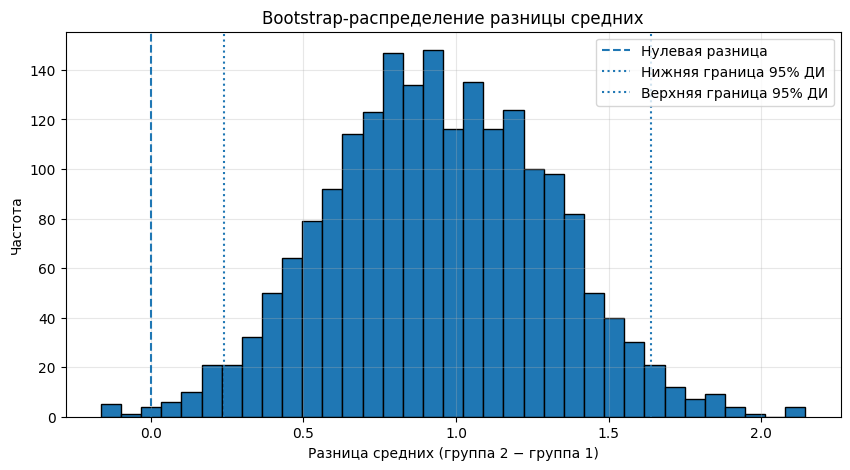

In [15]:
plt.figure(figsize=(10, 5))

plt.hist(
    bootstrap_differences,
    bins=35,
    edgecolor="black"
)

plt.axvline(0, linestyle="--", label="Нулевая разница")
plt.axvline(
    bootstrap_ci_low,
    linestyle=":",
    label="Нижняя граница 95% ДИ"
)
plt.axvline(
    bootstrap_ci_high,
    linestyle=":",
    label="Верхняя граница 95% ДИ"
)

plt.title("Bootstrap-распределение разницы средних")
plt.xlabel("Разница средних (группа 2 − группа 1)")
plt.ylabel("Частота")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Вывод

В ходе задания был проведён бутстрап-анализ с использованием 2000 повторных выборок с возвращением

Полученный 95% бутстрап-доверительный интервал для разницы средних составил **[0.2389; 1.6379]**. Интервал Уэлча из предыдущего задания составил **[0.2433; 1.6536]**

Границы двух интервалов практически совпадают. Оба интервала не включают ноль, что указывает на положительную разницу средних между группами: среднее второй группы выше среднего первой

Доля повторных выборок, в которых разница средних оказалась меньше или равна нулю, составила **0,35%**

Эту долю нельзя называть p-value, поскольку бутстрап-выборки формируются из исходных данных, а не при условии справедливости нулевой гипотезы. Это доля повторных выборок с неположительной разницей средних, а не классическое значение статистической значимости